# Manual ROC Curve and AUC Comparison

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

In [2]:
X, y = make_classification(n_samples=2000, n_features=15, n_informative=6,
                           class_sep=0.8, flip_y=0.05, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

In [3]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree':       DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=200, random_state=42),
    'Naive Bayes':         GaussianNB(),
}
scores = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    scores[name] = m.predict_proba(X_test)[:, 1]

In [4]:
def manual_roc(y_true, s):
    P, N = np.sum(y_true == 1), np.sum(y_true == 0)
    thresholds = np.concatenate(([np.inf], np.sort(np.unique(s))[::-1]))
    tpr, fpr = [], []
    for t in thresholds:
        pred = s >= t
        tpr.append(np.sum(pred & (y_true == 1)) / P)   # TP / (TP + FN)
        fpr.append(np.sum(pred & (y_true == 0)) / N)   # FP / (FP + TN)
    return thresholds, np.array(fpr), np.array(tpr)

roc = {name: manual_roc(y_test, s) for name, s in scores.items()}

In [5]:
def manual_auc(fpr, tpr):
    return np.sum((fpr[1:] - fpr[:-1]) * (tpr[1:] + tpr[:-1]) / 2)

auc = {name: manual_auc(f, t) for name, (_, f, t) in roc.items()}
for name, a in sorted(auc.items(), key=lambda x: -x[1]):
    print(f'{name:20s} AUC = {a:.4f}')

Random Forest        AUC = 0.9347
Decision Tree        AUC = 0.8915
Naive Bayes          AUC = 0.8908
Logistic Regression  AUC = 0.8418


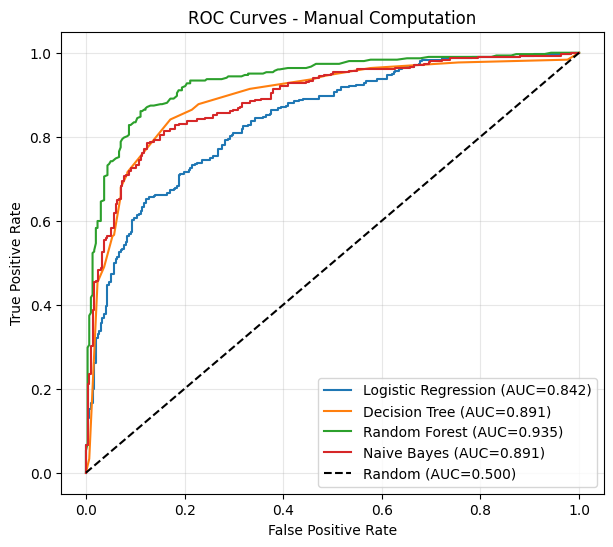

In [6]:
plt.figure(figsize=(7, 6))
for name, (_, f, t) in roc.items():
    plt.plot(f, t, label=f'{name} (AUC={auc[name]:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random (AUC=0.500)')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Manual Computation')
plt.legend(loc='lower right'); plt.grid(alpha=0.3)
plt.show()

In [7]:
print(f"{'Model':20s} {'Thr':>5s} {'TPR':>7s} {'FPR':>7s}")
for name, s in scores.items():
    for t in [0.3, 0.5, 0.7]:
        pred = s >= t
        tpr = np.sum(pred & (y_test == 1)) / np.sum(y_test == 1)
        fpr = np.sum(pred & (y_test == 0)) / np.sum(y_test == 0)
        print(f'{name:20s} {t:5.1f} {tpr:7.3f} {fpr:7.3f}')

Model                  Thr     TPR     FPR
Logistic Regression    0.3   0.887   0.433
Logistic Regression    0.5   0.732   0.218
Logistic Regression    0.7   0.526   0.070
Decision Tree          0.3   0.874   0.225
Decision Tree          0.5   0.864   0.215
Decision Tree          0.7   0.712   0.084
Random Forest          0.3   0.937   0.275
Random Forest          0.5   0.861   0.111
Random Forest          0.7   0.659   0.037
Naive Bayes            0.3   0.858   0.292
Naive Bayes            0.5   0.785   0.128
Naive Bayes            0.7   0.563   0.050


In [8]:
for name, (th, f, t) in roc.items():
    i = np.argmax(t >= 0.90)          # pehla point jahan TPR >= 0.90
    print(f'{name:20s} FPR = {f[i]:.3f} at threshold = {th[i]:.3f}')

Logistic Regression  FPR = 0.503 at threshold = 0.265
Decision Tree        FPR = 0.332 at threshold = 0.163
Random Forest        FPR = 0.185 at threshold = 0.410
Naive Bayes          FPR = 0.376 at threshold = 0.233


## Analysis
- **AUC** model ki overall ranking ability batata hai (threshold se independent). Jiska AUC zyada, wo positives ko negatives se behtar rank karta hai.
- **Threshold kam karne** pe TPR badhta hai (zyada positives pakde jaate hain) lekin FPR bhi badhta hai (zyada false alarms).
- **Decision Tree** ka ROC curve step jaisa hota hai kyunki uske probability scores kam unique hote hain.
- Cell 8 se pata chalta hai ki same recall (90%) ke liye kaun sa model sabse kam false alarms deta hai. Jahan false negative costly ho (jaise disease detection), wahan high TPR wala threshold chuno; jahan false positive costly ho (jaise spam filter), wahan low FPR wala.
- Sirf AUC dekhke model mat chuno, apne problem ke cost ke hisaab se threshold bhi decide karo.